# 01 – Exploratory Data Analysis
## Credit Risk – Probability of Default

# 1. Libs

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets

from pathlib import Path
from IPython.display import display, HTML
from IPython.display import display_html
from ucimlrepo import fetch_ucirepo

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

__Also telling pandas to show all columns and seaborn to use a white background.__

# 2. Data Loading

Loading the Default of Credit Card Clients dataset from the UCI Machine Learning Repository.


In [2]:
default_of_credit_card_clients = fetch_ucirepo(id=350)

X = default_of_credit_card_clients.data.features
y = default_of_credit_card_clients.data.targets

print("Predictors shape:", X.shape)
print("Target shape:", y.shape)

Predictors shape: (30000, 23)
Target shape: (30000, 1)


__We have 30,000 observations, 23 predictor variables, and 1 target variable.__

# 3. Data Preparation

Renaming the dataset columns using descriptive variable names based on the UCI documentation and combining the predictor variables with the target variable into a single DataFrame.


In [15]:
column_mapping = {
    "X1": "LIMIT_BAL",
    "X2": "SEX",
    "X3": "EDUCATION",
    "X4": "MARRIAGE",
    "X5": "AGE",
    "X6": "PAY_0",
    "X7": "PAY_2",
    "X8": "PAY_3",
    "X9": "PAY_4",
    "X10": "PAY_5",
    "X11": "PAY_6",
    "X12": "BILL_AMT1",
    "X13": "BILL_AMT2",
    "X14": "BILL_AMT3",
    "X15": "BILL_AMT4",
    "X16": "BILL_AMT5",
    "X17": "BILL_AMT6",
    "X18": "PAY_AMT1",
    "X19": "PAY_AMT2",
    "X20": "PAY_AMT3",
    "X21": "PAY_AMT4",
    "X22": "PAY_AMT5",
    "X23": "PAY_AMT6"
}

X = X.rename(columns=column_mapping)

df = pd.concat([X, y], axis=1)

target = y.columns[0]
  
df.head()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,Y
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


__Now we have descriptive names for our predictors.__

__For further information, please visit__ _notebooks/Data Dictionary — Credit Risk - Probability of Default.md_ 

In [ ]:
# saving the dataset

data_dir = Path("../data/processed")
data_dir.mkdir(parents=True, exist_ok=True)

df.to_parquet(data_dir / "credit_default_eda.parquet", index=False

# 4. Initial Data Inspection

Inspecting the dataset structure, including its dimensions, column names, data types and missing values, to assess data consistency and identify potential data quality issues.
    

In [4]:
print("Dataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

data_types = df.dtypes.to_frame(name="data_type")

missing_values = (
    df.isnull()
      .sum()
      .to_frame(name="missing_values")
)

display(HTML("""
<style>
.table-container {
    display: flex;
    gap: 30px;
    align-items: flex-start;
}
</style>
"""))

display(HTML(
    f"""
    <div class="table-container">
        <div>
            <h4>Data Types</h4>
            {data_types.to_html()}
        </div>
        <div>
            <h4>Missing Values</h4>
            {missing_values.to_html()}
        </div>
    </div>
    """
))

Dataset dimensions: (30000, 24)

Column names:
['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'Y']


,data_type
LIMIT_BAL,int64
SEX,int64
EDUCATION,int64
MARRIAGE,int64
AGE,int64
PAY_0,int64
PAY_2,int64
PAY_3,int64
PAY_4,int64
PAY_5,int64


__Perfect. The inspection confirms three important points:__

1. Dimensions: 30,000 observations and 24 columns, as expected.
2. Missing values: no variable contains NaNs.
3. Data types: all columns are stored as int64.
   
__One caveat: int64 describes the storage format, not the statistical nature of the variable. SEX, EDUCATION, and MARRIAGE, for example, remain categorical.__

# 5. Target Variable Analysis

Analyzing the target variable distribution to understand the proportion of default and non-default observations and assess class imbalance.

In [5]:
left = widgets.Output()
right = widgets.Output()

# Output da tabela
with left:
    target_distribution = pd.DataFrame({
        "count": df[target].value_counts().sort_index(),
        "percentage": df[target].value_counts(normalize=True).sort_index() * 100
    })

    display(target_distribution)

# Output do gráfico
with right:
    plt.figure(figsize=(7, 5))

    sns.countplot(data=df, x=target)

    plt.title("Distribution of Credit Default")
    plt.xlabel("Default in the following month")
    plt.ylabel("Number of clients")

    plt.show()

display(widgets.HBox([left, right]))

__This represents approximately 3.52 non-defaulting clients for every one who defaults.__

__We therefore have a moderate imbalance. While this does not automatically necessitate techniques such as SMOTE or undersampling, we will need to be careful when evaluating our models.__

__For instance, a model that always predicted 0 would achieve 77.88% accuracy, yet it would fail to identify any defaulting clients. Consequently, we cannot rely solely on accuracy to evaluate our model.__

# 6. Descriptive Statistics of Numerical Variables

Generating descriptive statistics for numerical variables, including measures of central tendency, dispersion, and range, to understand their distributions and identify potential outliers.

In [6]:
numeric_columns = [
    "LIMIT_BAL",
    "AGE",
    "BILL_AMT1",
    "BILL_AMT2",
    "BILL_AMT3",
    "BILL_AMT4",
    "BILL_AMT5",
    "BILL_AMT6",
    "PAY_AMT1",
    "PAY_AMT2",
    "PAY_AMT3",
    "PAY_AMT4",
    "PAY_AMT5",
    "PAY_AMT6"
]

numeric_summary = df[numeric_columns].describe().T

display(numeric_summary)

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
BILL_AMT1,30000.0,51223.330900,73635.860576,-165580.0,3558.75,22381.5,67091.00,964511.0
BILL_AMT2,30000.0,49179.075167,71173.768783,-69777.0,2984.75,21200.0,64006.25,983931.0
BILL_AMT3,30000.0,47013.154800,69349.387427,-157264.0,2666.25,20088.5,60164.75,1664089.0
BILL_AMT4,30000.0,43262.948967,64332.856134,-170000.0,2326.75,19052.0,54506.00,891586.0
BILL_AMT5,30000.0,40311.400967,60797.155770,-81334.0,1763.00,18104.5,50190.50,927171.0
BILL_AMT6,30000.0,38871.760400,59554.107537,-339603.0,1256.00,17071.0,49198.25,961664.0
PAY_AMT1,30000.0,5663.580500,16563.280354,0.0,1000.00,2100.0,5006.00,873552.0
PAY_AMT2,30000.0,5921.163500,23040.870402,0.0,833.00,2009.0,5000.00,1684259.0


__This table already reveals some important patterns. We should not remove any extreme values at this stage; first, we need to determine whether they are valid and how they affect the distribution.__

What the results show:
   
__LIMIT_BAL — credit limit__
- Mean: __NT 167,484__
- Median: __NT 140,000__
- Maximum: __NT 1,000,000__

The fact that the mean is higher than the median suggests a right-skewed distribution: some clients have very high credit limits.

__AGE — age__
- Mean: __35.49 years__
- Median: __34 years__
- Maximum: __79 years__

The distribution appears less skewed than the other variables, though we still need to visualize the data.

__BILL_AMT1 to BILL_AMT6 — bill amounts__

An interesting observation here: the means range from approximately __NT 38,000__ to __NT 51,000__, while the medians fall between __NT 1,200__ and __NT 3,600__.

This discrepancy suggests highly skewed distributions, with some very large values.

There are also negative values, such as BILL_AMT6 = -339,603. We should not automatically classify these as errors; they could represent credit balances or account adjustments. We need to verify their meaning before deciding how to handle them.

__PAY_AMT1 to PAY_AMT6 — payment amounts__

- The medians are relatively low, ranging from approximately __NT 252__ to __NT 1,000__.
- The means are significantly higher.
- There are very high maximum values, reaching up to __NT 1,684,259__.
- The minimum value is zero for all periods.
  
This points to a strong right skew and suggests that many clients may not have made any payments during certain periods. The analysis confirms that several variables exhibit strong right-skewness, particularly the bill amounts (BILL_AMT) and payment amounts (PAY_AMT).

This is evident from the difference between the mean and the median. For example:

- PAY_AMT2: a mean of approximately __NT 5,921__, but a median of __NT 833__.
- BILL_AMT1: a mean of approximately __NT 51,223__, but a median of __NT 22, 381__.
- LIMIT_BAL: a mean of __NT 167,484__, with a median of __NT 140,000__.
  
This indicates that some clients have values significantly higher than those of the majority.

Next, lets investigate the negative values on the __BILL_AMT*__ variables.

# 7. Detection of Negative Bill Amounts

Checking the frequency of negative values in monthly bill statement amounts to identify potentially relevant account balances or anomalies that require further investigation.

In [7]:
bill_columns = [f"BILL_AMT{i}" for i in range(1, 7)]

negative_bill_values = (
    df[bill_columns]
    .lt(0)
    .sum()
    .to_frame(name="negative_values")
)

display(negative_bill_values)

,negative_values
BILL_AMT1,590
BILL_AMT2,669
BILL_AMT3,655
BILL_AMT4,675
BILL_AMT5,655
BILL_AMT6,688


__The results show that negative values appear in all six periods, but they represent a small portion of the dataset.__

Variable	Negative values	% of 30,000 customers
BILL_AMT1	590	1.97%
BILL_AMT2	669	2.23%
BILL_AMT3	655	2.18%
BILL_AMT4	675	2.25%
BILL_AMT5	655	2.18%
BILL_AMT6	688	2.29%

__What can we conclude?__

1. These do not appear to be isolated occurrences limited to a single month.
   
2. The proportion is relatively stable, ranging between 1.97% and 2.29%.

3. We do not have sufficient evidence to classify them as errors or to remove them.

__One possible interpretation is that they represent credit balances on the card account—for instance, resulting from overpayments or adjustments. However, we need to verify this hypothesis against what the documentation actually confirms.__

__Let's investigate this further by examining its relationship with our target variable.__

# 8. Default Rate Analysis of Negative Bill Amounts

Comparing default rates between clients with negative and non-negative monthly bill statement amounts to investigate whether negative balances are associated with different credit risk profiles.

In [8]:
results = []

for col in bill_columns:

    negative_col = f"{col}_NEGATIVE"
    df[negative_col] = df[col] < 0

    result = (
        df.groupby(negative_col)[target]
        .agg(["count", "mean"])
        .rename(columns={
            "count": "number_of_clients",
            "mean": "default_rate"
        })
    )

    result["default_rate"] *= 100

    results.append(
        f"<h4>{col}</h4>" + result.to_html(float_format=lambda x: f"{x:.2f}")
    )

left_column = "".join(results[:3])
right_column = "".join(results[3:])

html = f"""
<div style="display: flex; gap: 30px;">
    <div style="flex: 1;">{left_column}</div>
    <div style="flex: 1;">{right_column}</div>
</div>
"""

display_html(html, raw=True)

,number_of_clients,default_rate
BILL_AMT1_NEGATIVE,,
False,29410,22.19
True,590,18.47
,number_of_clients,default_rate
BILL_AMT2_NEGATIVE,,
False,29331,22.19
True,669,18.98
,number_of_clients,default_rate
BILL_AMT3_NEGATIVE,,
False,29345,22.17


__We observe a consistent pattern: negative invoice amounts are associated with a lower default rate within this sample.__

__This could be consistent with the hypothesis that these customers hold credit balances in their accounts. However, it remains unclear whether this characteristic truly reflects distinct financial behavior or if it is linked to other variables.__

__We must also take into account that these groups are small, representing approximately 2% of customers in each period.__

__My decision for now: keep the negative values. We have no justification for removing or replacing them.__

__Later, let's also create a feature based on negative bill amounts that could be useful for our model later.__

# 9. Numerical Variable Distributions

Visualizing the distributions of credit limits and customer ages using histograms to examine their shapes, concentration, spread, and potential skewness or outliers.

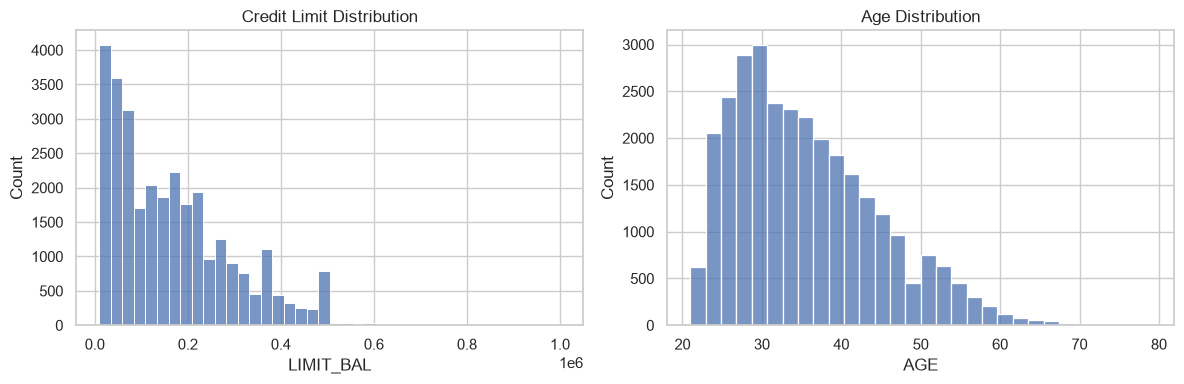

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=df, x="LIMIT_BAL", bins=40, ax=axes[0])
axes[0].set_title("Credit Limit Distribution")

sns.histplot(data=df, x="AGE", bins=30, ax=axes[1])
axes[1].set_title("Age Distribution")

plt.tight_layout()
plt.show()

# 10. Monthly Bill Amount Distributions

Visualizing the distributions of monthly bill statement amounts using histograms to examine their shapes, variability, skewness, and potential outliers across the six billing periods.

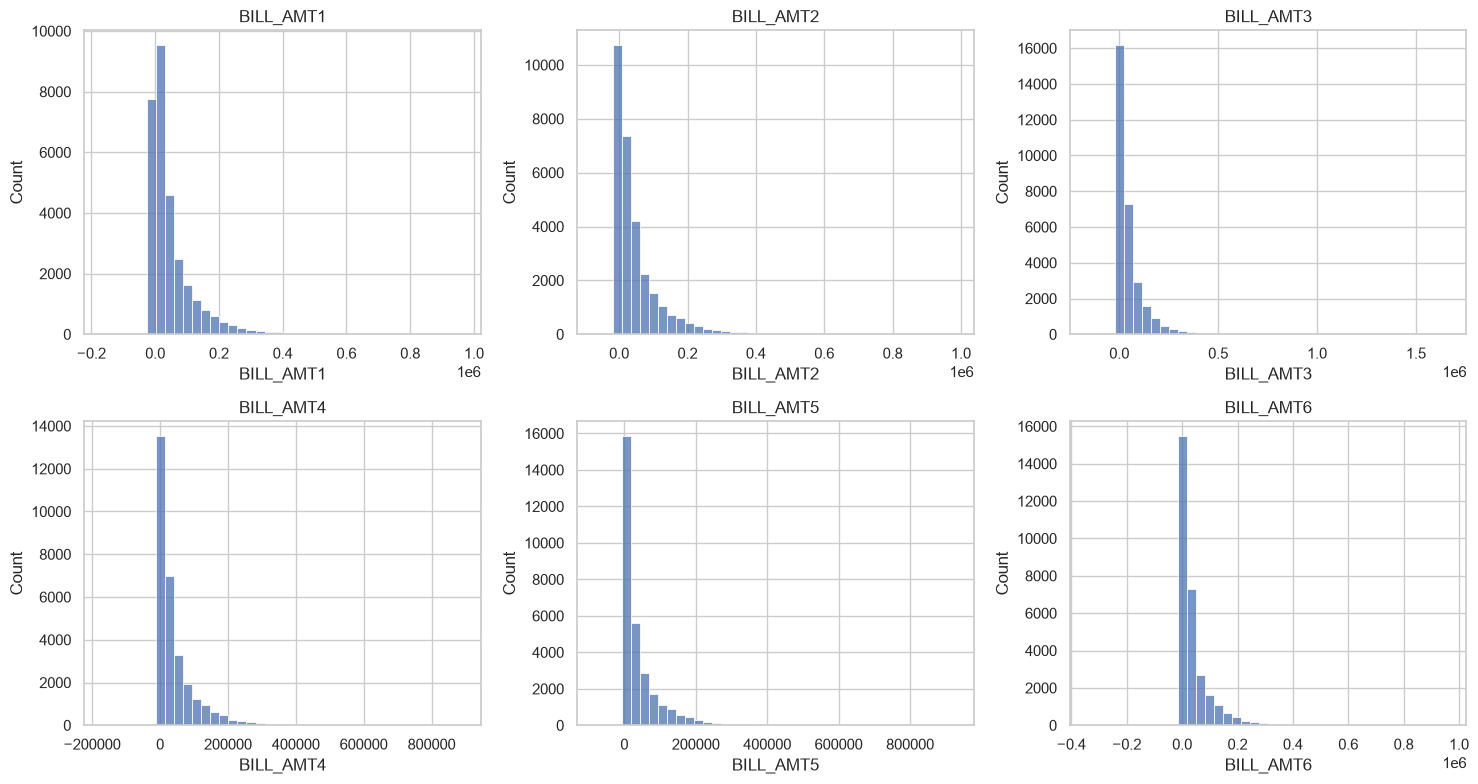

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flat, bill_columns):
    sns.histplot(data=df, x=col, bins=40, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

# 11. Monthly Payment Amount Distributions

Visualizing the distributions of monthly payment amounts using histograms to examine their shapes, variability, skewness, and potential outliers across the six billing periods.

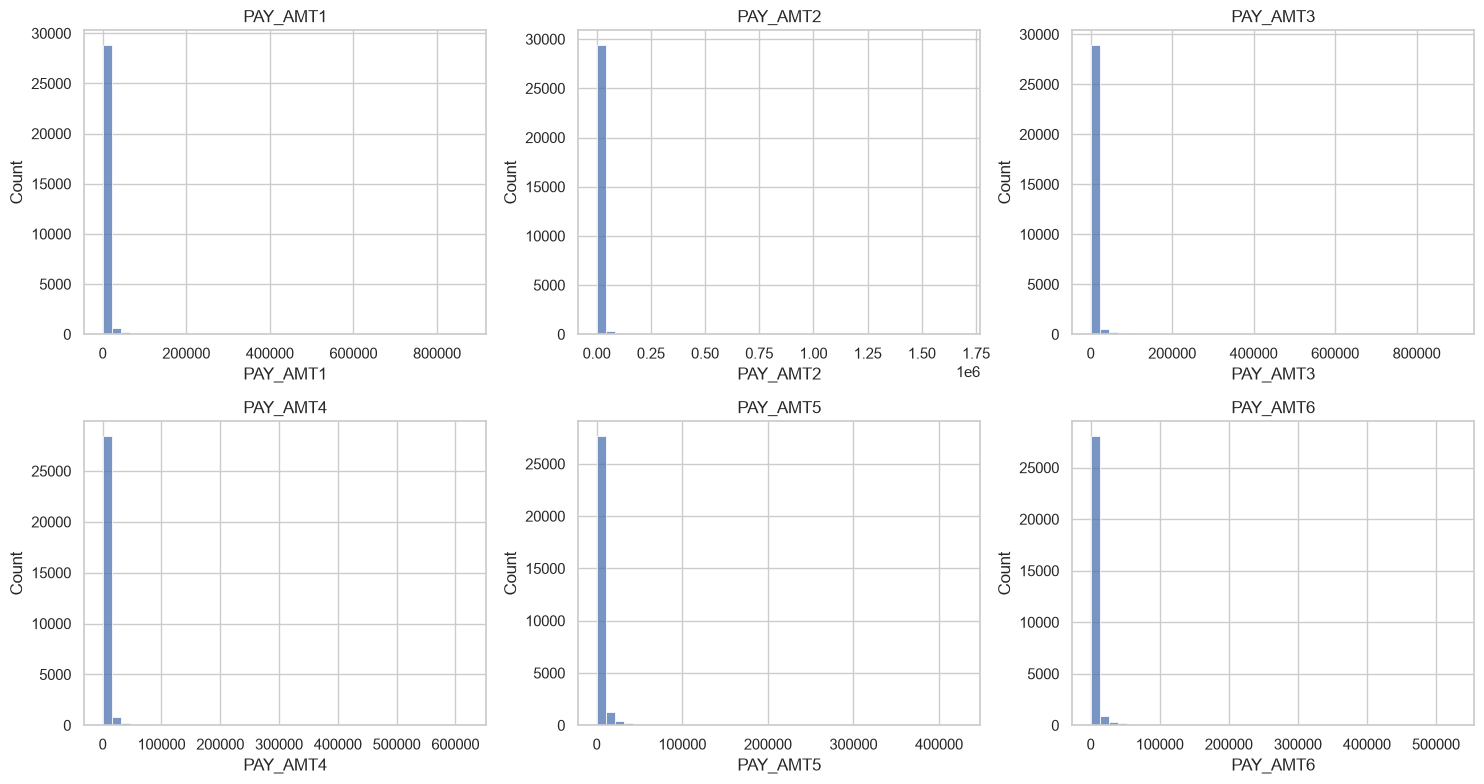

In [11]:
# VALORES DOS PAGAMENTOS

payment_columns = [f"PAY_AMT{i}" for i in range(1, 7)]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flat, payment_columns):
    sns.histplot(data=df, x=col, bins=40, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()